# Exercise 1: Predicting house prices with linear models

In this exercise, we return to the Ames housing data from Lectures 1 and 2.
We examine whether regularization can improve predictions of (log) sale prices over the OLS benchmark.

The following cell defines the global variables used throughout the notebook. You should change the number of jobs to run in parallel (`NUM_JOBS`) to adapt to your system. 

In [1]:
# Random state used for sample splitting (train/test, cross-validation) and other RNGs
RANDOM_STATE = 1234

# Scoring metric for cross-validation
SCORING = 'neg_root_mean_squared_error'

# Number of jobs to run in parallel (ADAPT TO YOUR SYSTEM!)
NUM_JOBS = 4

## Data description

The following cell loads the Ames housing data from the file 
[`data/ames_houses.csv`](../../data/ames_houses.csv).
The table below summarizes the variables used in this exercise.

In [2]:
import pandas as pd

file = '../../data/ames_houses.csv'
df_ames = pd.read_csv(file)

print(f'Number of observations in the common sample: {len(df_ames):,d}')

Number of observations in the common sample: 2,930


The data contain the following house characteristics and sale information:

| Variables | Description |
| :--- | :--- |
| `SalePrice` | Sale price, in thousands of USD |
| `LivingArea`, `LotArea` | Above-ground living area and lot area, in m² |
| `BasementArea`, `FinishedBasementArea` | Total and finished basement area, in m² |
| `YearBuilt`, `YearRemodeled` | Construction year and most recent remodel year |
| `OverallQuality`, `OverallCondition` | Ratings from 1 to 10 |
| `ExteriorQuality` | Exterior material quality, recorded as text |
| `Bathrooms`, `Bedrooms`, `Fireplaces` | Numbers of rooms and fireplaces |
| `BuildingType` | Type of dwelling |
| `CentralAir`, `HasGarage` | Air conditioning and garage indicators |
| `YearSold`, `MonthSold` | Year and month of sale |

Finished basement area is the part of total basement area finished as living
space. Basement areas can be zero, so these variables remain in levels.

***
## Part 1 — Prepare the data

As a first step, you need to prepare the data for modeling. The following steps are required:

1. Remove rows with missing values.
2. Remove houses with lot areas above 10,000 m² or living areas above 350 m².
3. Create `logSalePrice`, `logLivingArea`, and `logLotArea` using natural logs.
4. Split the full DataFrame into `df_train` and `df_test`, reserving 50% of the
   observations for testing with `random_state=1234`.
5. Define `y_train` and `y_test` using `logSalePrice` as the target.

### Solution

#### Applying the sample restrictions

In a first step, we drop all rows with missing values. We could of course do this in one line with `dropna()`, but we want to document the number of rows dropped for each variable.

In [3]:
# Drop rows with missing values. Document the number dropped at each step.
columns = sorted(df_ames.columns)
for column in columns:
    n_missing = df_ames[column].isna().sum()
    if n_missing > 0:
        print(f'Dropping {n_missing:3,d} rows with missing values in {column}')
        df_ames = df_ames.dropna(subset=[column]).copy()

Dropping   1 rows with missing values in BasementArea


Next, we remove extreme outliers for lot area and living area, again documenting the number of rows dropped. 

In [4]:
# Drop extreme outliers for lot area
drop = df_ames['LotArea'] > 10_000
print(f'Dropping {drop.sum():3,d} rows with LotArea above 10,000 m²')
df_ames = df_ames[~drop].copy()

# Drop houses with living area above 350 square meters
drop = df_ames['LivingArea'] > 350
print(f'Dropping {drop.sum():3,d} rows with LivingArea above 350 m²')
df_ames = df_ames[~drop].copy()

Dropping   4 rows with LotArea above 10,000 m²
Dropping   6 rows with LivingArea above 350 m²


#### Log transformations 

Taking a log applies a fixed rule to each observation; it estimates no sample
statistics. The logged columns can therefore be created before splitting the
sample. The target variable is `logSalePrice`.

In [5]:
import numpy as np

for col in ['SalePrice', 'LivingArea', 'LotArea']:
    df_ames[f'log{col}'] = np.log(df_ames[col])

#### Train-test split

Finally, we split the data into training and test sets, using the random state defined above.

In [6]:
from sklearn.model_selection import train_test_split

# Fraction allocated to test set
test_size = 0.5

# Split the full data once, retaining columns needed for plots and later models
df_train, df_test = train_test_split(
    df_ames, test_size=test_size, random_state=RANDOM_STATE
)

# Name of the target variable
target = 'logSalePrice'

# Define the target variable for training and test sets
y_train = df_train[target]
y_test = df_test[target]

print(f'Training observations: {len(df_train):,d}')
print(f'Test observations: {len(df_test):,d}')

Training observations: 1,459
Test observations: 1,460


<span style="display: none;">SolutionEnd</span>

***
## Part 2 — Explore the training data

1. Use the provided `plot_histograms()` to compare the distributions of sale
   price, living area, and lot area in levels and logs. What changes after
   taking logs?
2. Use the provided `plot_scatterplots()` to plot log sale price against the
   numeric candidate predictors. Discuss the relationships, unusual
   observations, and possible predictive information.
3. Report each predictor's correlation with log price. Which associations are
   strongest, and how do they compare with the scatter plots?

Base this exploratory analysis on the training data only!

In [7]:
import matplotlib.pyplot as plt


def plot_histograms(df_data, title=None):
    """
    Plot a histogram for every column in a DataFrame.

    Parameters
    ----------
    df_data : DataFrame
        Numeric columns to plot
    title : str or None
        Optional title for the entire figure
    """
    ncols = df_data.shape[1]
    figsize = (3 * ncols, 2.8)
    fig, axes = plt.subplots(
        1, ncols, figsize=figsize, layout='constrained', squeeze=False
    )
    for i, col in enumerate(df_data.columns):
        ax = axes[0, i]
        ax.hist(df_data[col], bins=40, color='steelblue', ec='white', lw=0.4)
        ax.set_xlabel(col)
        ax.set_ylabel('Number of houses')

    if title is not None:
        fig.suptitle(title)

In [8]:
def plot_scatterplots(y_var, df_data):
    """
    Plot one column against every other column in a DataFrame.

    Parameters
    ----------
    y_var : str
        Column name to use on the shared y-axis
    df_data : DataFrame
        Data containing the outcome and numeric predictors
    """
    columns = df_data.columns.drop(y_var)
    nplots = len(columns)
    ncols = min(4, nplots)
    nrows = (nplots + 3) // 4
    figsize = (2.25 * ncols, 2.25 * nrows)
    _, axes = plt.subplots(
        nrows, ncols, figsize=figsize, sharey=True, squeeze=False, layout='constrained'
    )
    axes = axes.ravel()

    for i, col in enumerate(columns):
        ax = axes[i]
        # Data to be plotted in this panel
        df_ = df_data[[col, y_var]]
        # Scatter plot with individual data points
        ax.scatter(df_[col], df_[y_var], s=8, alpha=0.3, c='steelblue')

        uniq = df_[col].nunique()
        if uniq <= 12:
            # Treat this as a categorical variable
            means = df_.groupby(col)[y_var].mean()
            xbin, ybin = means.index, means
            ax.set_xticks(sorted(df_data[col].unique()))
        else:
            # Continuous variable
            bins = pd.cut(df_[col], bins=10)
            means = df_.groupby(bins).mean()
            xbin, ybin = means[col], means[y_var]
            ax.locator_params(axis='x', nbins=4)

        # Plot bin scatter plot
        ax.plot(xbin, ybin, marker='o', c='black', lw=1, ls='--', ms=3)

        ax.set_xlabel(col)
        if i % 4 == 0:
            ax.set_ylabel(y_var)
        corr = np.corrcoef(df_data[col], df_data[y_var])[0, 1]
        ax.text(
            0.95,
            0.05,
            f'corr = {corr:.2f}',
            transform=ax.transAxes,
            va='bottom',
            ha='right',
            fontsize=8,
        )

    for ax in axes[nplots:]:
        ax.set_visible(False)

### Solution

#### Distributions in the training sample

These plots use only the training observations. Living area and especially lot area
have long right tails. Logs compress these tails and make the bulk of the
distributions easier to see.

In econometrics, we often apply logs to outcome and predictor variables. This allows us
to interpret coefficients as elasticities, although our focus here is prediction.

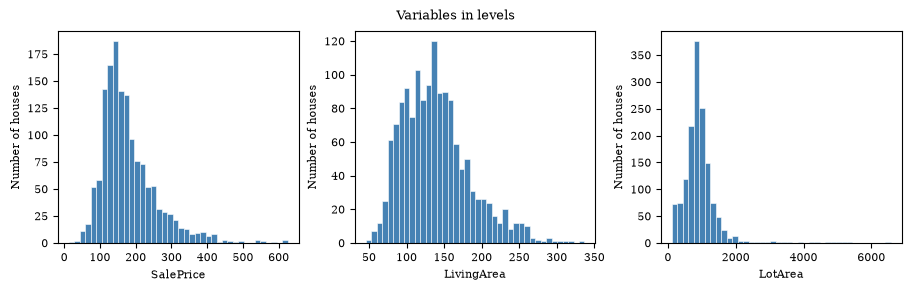

In [9]:
columns = ['SalePrice', 'LivingArea', 'LotArea']
plot_histograms(df_train[columns], title='Variables in levels')

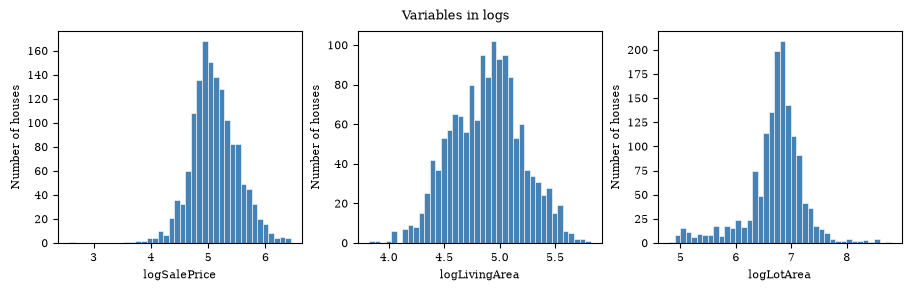

In [10]:
columns = ['logSalePrice', 'logLivingArea', 'logLotArea']
plot_histograms(df_train[columns], title='Variables in logs')

#### Relationships with log price

The scatter plots cover the numeric candidate predictors, including ratings,
counts, and sale dates. The original sale price is excluded because it is the
outcome used to construct log price.

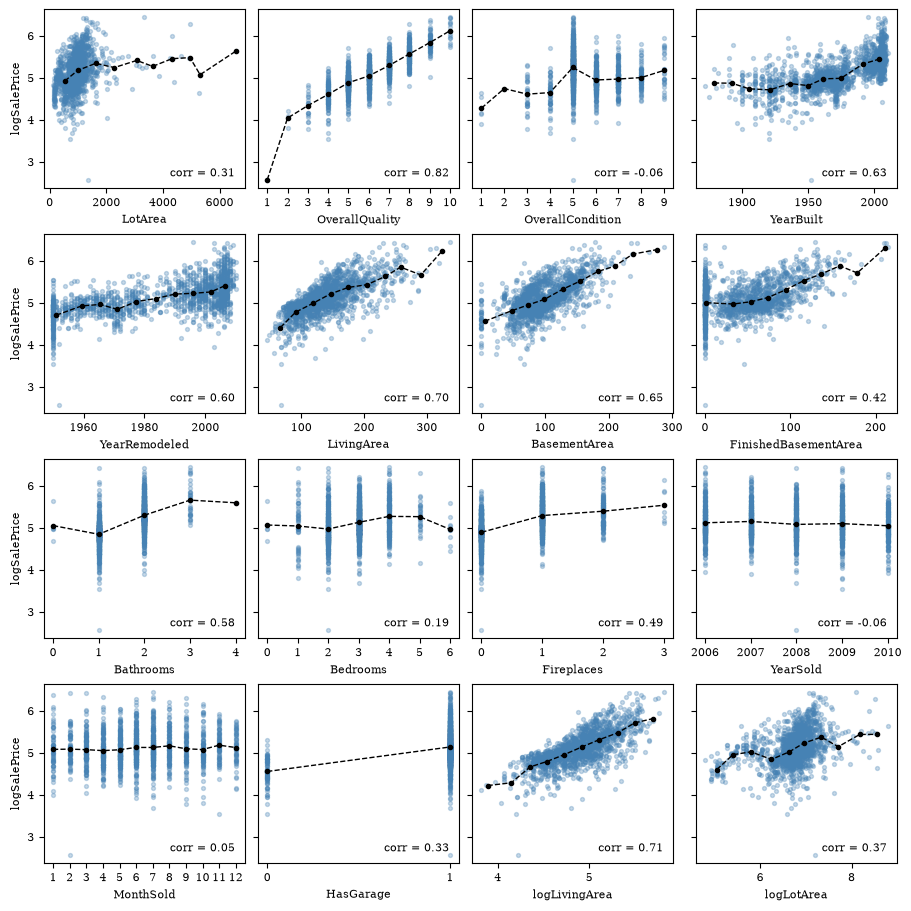

In [11]:
# Select numeric columns for EDA
df_eda = df_train.select_dtypes(include='number')

# Drop the target in levels so it's not included in the scatterplots
df_eda = df_eda.drop(columns=['SalePrice'])

# Plot scatterplots of the (log) target against all numeric predictors
plot_scatterplots(target, df_eda)


The correlation ranking summarizes each predictor's linear association with
log price. The plots can also reveal nonlinear relationships and unusual
observations.

In [12]:
# Compute correlations of all numeric predictors with the target variable
corr_price = df_eda.corrwith(df_eda[target]).drop(target)

# Tabulate correlations in descending order of absolute value
print(corr_price.sort_values(ascending=False, key=abs).round(2).to_string())

OverallQuality          0.82
logLivingArea           0.71
LivingArea              0.70
BasementArea            0.65
YearBuilt               0.63
YearRemodeled           0.60
Bathrooms               0.58
Fireplaces              0.49
FinishedBasementArea    0.42
logLotArea              0.37
HasGarage               0.33
LotArea                 0.31
Bedrooms                0.19
OverallCondition       -0.06
YearSold               -0.06
MonthSold               0.05


The correlation ranking highlights overall quality, living area, basement area, and
construction year as potentially important predictors. On the other hand, overall
condition and the month and year when a house was sold are only weakly correlated
with log price.

The models below use the numeric house characteristics, with living and lot
area in logs. Year and month of sale are excluded. Overall condition is included
because it improves predictive performance despite its weak marginal correlation.

<span style="display: none;">SolutionEnd</span>

***
## Part 3 — Ordinary least squares

Use the predictors listed below throughout the model comparison.

1. Implement the function `make_model(estimator)` to build a model that can be used for estimation.

   The function should build a pipeline
   with input standardization, polynomial expansion, a second standardization,
   and use the given `estimator` as the final step.
   
2. Check how many features a polynomial expansion with degrees 1, 2, and 3 generates.

   *Hint:* This number is stored in the attribute `n_output_features_` of a fitted `PolynomialFeatures` object.

3. Select the optimal polynomial degree using cross-validation with
   [`GridSearchCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html),
   specifying a parameter grid of 1, 2, and 3,
   `scoring='neg_root_mean_squared_error'`, and `return_train_score=True`.
   Use `make_model()` to build the model to be cross-validated, passing
   `LinearRegression()` as the estimator.

   Use a CV splitter using `KFold` with five shuffled folds with `random_state=1234`
   
4. Report the selected degree and CV RMSE. Use the provided
   `plot_ols_validation_curve()` to compare training and validation errors.

In [13]:
def make_model(estimator):
    """Build a polynomial regression pipeline."""
    # TODO: Add input scaling, polynomial expansion, and output scaling
    # TODO: Add the supplied estimator as the final step named 'model'
    # TODO: Return the pipeline

In [14]:
# Numeric predictors; living and lot area enter in logs
features = [
    'logLivingArea',
    'logLotArea',
    'YearBuilt',
    'YearRemodeled',
    'BasementArea',
    'FinishedBasementArea',
    'OverallQuality',
    'OverallCondition',
    'Bathrooms',
    'Bedrooms',
    'Fireplaces',
    'HasGarage',
]

# Training and test data for the selected features
X_train = df_train[features]
X_test = df_test[features]

In [15]:
def plot_ols_validation_curve(ols_cv):
    """
    Plot training and validation RMSE against polynomial degree.

    Parameters
    ----------
    ols_cv : GridSearchCV
        Fitted GridSearchCV object for OLS regression
    """
    import matplotlib.pyplot as plt

    df_ols = pd.DataFrame(ols_cv.cv_results_)
    degrees = df_ols['param_poly__degree']
    train_score = -df_ols['mean_train_score']
    test_score = -df_ols['mean_test_score']
    _, ax = plt.subplots(figsize=(5, 3), layout='constrained')

    colors = ['#1f78b4','#e31a1c', '#33a02c']

    ax.plot(degrees, train_score, c=colors[0], marker='o', label='Training')
    ax.plot(degrees, test_score, c=colors[1], marker='o', label='Validation')
    ax.set_xticks(degrees)
    ax.set_xlabel('Polynomial degree')
    ax.set_ylabel('RMSE in log prices')
    ax.set_title('Validation curve for polynomial degree')
    ax.legend()

### Solution

#### Implementing the `make_model()` function

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


def make_model(estimator):
    """
    Build a polynomial regression pipeline.

    Parameters
    ----------
    estimator : object
        Regression estimator used after preprocessing

    Returns
    -------
    Unfitted pipeline containing preprocessing and regression
    """
    pipe = Pipeline(
        [
            ('input_scale', StandardScaler()),
            ('poly', PolynomialFeatures(include_bias=False)),
            ('scale', StandardScaler()),
            ('model', estimator),
        ]
    )
    return pipe

#### Number of polynomial features

The following cell reports the number of features generated by the polynomial expansion. 
Some are redundant: powers of the garage indicator add no information,
although its interactions with other predictors can be useful.

In [17]:
for degree in [1, 2, 3]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    poly.fit(X_train)
    print(f'Degree {degree}: {poly.n_output_features_:3d} polynomial columns')

Degree 1:  12 polynomial columns
Degree 2:  90 polynomial columns
Degree 3: 454 polynomial columns


#### Cross-validation

The following code defines the CV splitter, scoring metric, the parameter grid to search over, and the estimator pipeline to cross-validate.

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold

# Splitter used for cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Scoring metric used for cross-validation
scoring = SCORING

# Candidate polynomial degrees
degrees = [1, 2, 3]

# Parameter grid
param_grid = {'poly__degree': degrees}

# Estimator pipeline for OLS
pipe_ols = make_model(LinearRegression())

We can then create the `GridSearchCV` object and run cross-validation using the `fit()` method.

In [19]:
# Define the GridSearchCV object for OLS
ols_cv = GridSearchCV(
    pipe_ols,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit=True,
    return_train_score=True,
    n_jobs=NUM_JOBS,
)

# Run cross-validation
ols_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'poly__degree': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r

#### Cross-validation results and validation curve

After the fitting is complete, we extract the selected polynomial degree from the `best_params_` attribute of the fitted `GridSearchCV` object, and the best CV RMSE from the `best_score_` attribute. The reported CV score is the mean of the five fold RMSEs.

In [20]:
# Store the best polynomial degree
degree_ols = ols_cv.best_params_['poly__degree']

# Store the best CV RMSE
rmse_ols = -ols_cv.best_score_

print(f'OLS polynomial degree: {degree_ols}')
print(f'OLS CV RMSE: {rmse_ols:.4f}')

OLS polynomial degree: 1
OLS CV RMSE: 0.1346


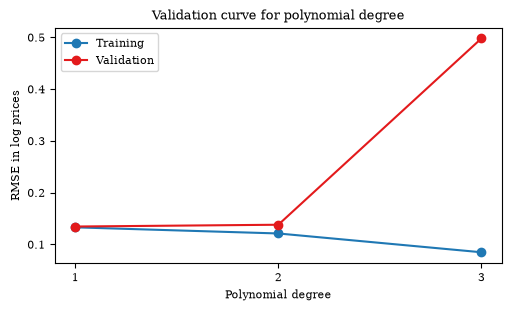

In [21]:
plot_ols_validation_curve(ols_cv)

<span style="display: none;">SolutionEnd</span>

***
## Part 4 — Ridge regression

You are now going to repeat the cross-validation task with Ridge regression.

1. Replace OLS with
   [`Ridge()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).
   Select degree and the Ridge penalty alpha jointly, using degrees 1, 2, and 3 and
   100 log-spaced alphas from $10^{-2}$ to $10^2$.
   How many parameter combinations and fold fits does the search require?
2. Report the selected parameters and CV RMSE. 
3. Use the provided `plot_validation_curves()` to plot the validation curves.
   Do different degrees favor different penalties? Check whether the selected
   alpha is at a grid endpoint.

In [22]:
def plot_validation_curves(search, model_name):
    """
    Plot validation RMSE against alpha for each polynomial degree.

    Parameters
    ----------
    search : object
        Fitted grid search over polynomial degree and model alpha
    model_name : str
        Model name used in the plot title
    """
    df_results = pd.DataFrame(search.cv_results_)
    degree_col = 'param_poly__degree'
    colors = ['#1f78b4','#e31a1c', '#33a02c']

    _, ax = plt.subplots(figsize=(5.5, 3.2), layout='constrained')
    for i, (degree, df_group) in enumerate(df_results.groupby(degree_col)):
        df_group = df_group.sort_values('param_model__alpha')
        alphas = df_group['param_model__alpha']
        rmse = -df_group['mean_test_score']
        ax.plot(alphas, rmse, c=colors[i], label=f'Degree {degree}')

    best = df_results.loc[search.best_index_]
    ax.scatter(
        best['param_model__alpha'], -best['mean_test_score'], c='black', zorder=3
    )
    ax.set_xscale('log')
    ax.set_xlabel(r'Regularization strength $\alpha$')
    ax.set_ylabel('CV RMSE in log prices')
    ax.set_title(f'Validation curve for {model_name}')
    ax.legend()

### Solution

#### Ridge cross-validation

The Ridge grid contains $3 \times 100 = 300$ combinations, requiring 1,500
fold fits and one final refit.

Both hyperparameters are selected together. The OLS degree is not held fixed
for Ridge: regularization can change which degree predicts best.

In [23]:
from sklearn.linear_model import Ridge

# Define the candidate alphas for Ridge regression
ridge_alphas = np.logspace(-2, 2, num=100)

# Define the parameter grid for Ridge regression
ridge_param_grid = {'poly__degree': degrees, 'model__alpha': ridge_alphas}

# Define the Ridge regression pipeline
pipe_ridge = make_model(Ridge())

In [24]:
# Define the GridSearchCV object for Ridge regression
ridge_cv = GridSearchCV(
    pipe_ridge,
    param_grid=ridge_param_grid,
    cv=cv,
    scoring=scoring,
    refit=True,
    n_jobs=NUM_JOBS,
)

# Run cross-validation
ridge_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': array([1.0000...00000000e+02]), 'poly__degree': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True

#### Cross-validation results

In [25]:
alpha_ridge = ridge_cv.best_params_['model__alpha']
degree_ridge = ridge_cv.best_params_['poly__degree']
rmse_ridge = -ridge_cv.best_score_

print(f'Ridge polynomial degree: {degree_ridge}')
print(f'Ridge CV alpha: {alpha_ridge:.4g}')
print(f'Ridge CV RMSE: {rmse_ridge:.4g}')


Ridge polynomial degree: 1
Ridge CV alpha: 4.642
Ridge CV RMSE: 0.1346


#### Validation curve

Each curve holds the degree fixed and varies $\alpha$. The black point
marks the best combination across all curves.

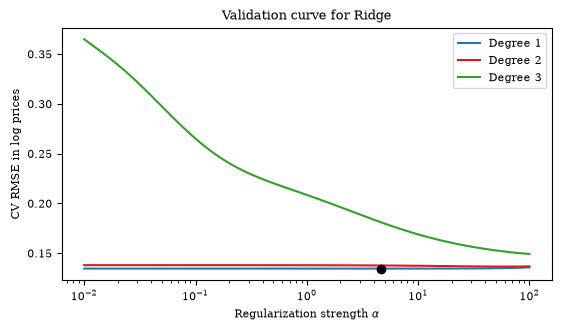

In [26]:
plot_validation_curves(ridge_cv, 'Ridge')

Different degrees favor different penalties. For degree 3, the curve is still
falling at the upper end of the grid, suggesting that a larger alpha would
improve this specification. The selected alpha for the best model (degree 1)
is clearly inside the grid. If it were at either endpoint, we would need to
expand the grid.

<span style="display: none;">SolutionEnd</span>

***
## Part 5 — Lasso

In this part, you will repeat the cross-validation task with Lasso regression.

1. Use
   [`Lasso()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html)
   with the same predictors, pipeline transformations, folds, and scorer.
   Select degree jointly with 100 log-spaced alphas from $10^{-4}$ to $10^{-1}$.
2. Report the selected parameters, CV RMSE, and number of nonzero coefficients.
3. Use the provided `plot_validation_curves()` to plot the validation curves
   and check the alpha grid endpoints.

Use `max_iter=1_000_000`, `tol=1e-6`, `precompute=True`,
`selection='random'`, and the fixed random seed. Revisit the solver settings
if convergence warnings appear.

### Solution

#### Cross-validation

The larger iteration limit lets the solver finish for weak penalties;
`precompute=True` speeds up these fits.

In [27]:
from sklearn.linear_model import Lasso

# Define the candidate alphas for Lasso regression
lasso_alphas = np.logspace(-4, -1, num=100)

# Define the parameter grid for Lasso regression
lasso_param_grid = {'poly__degree': degrees, 'model__alpha': lasso_alphas}

# Define the Lasso estimator as last step in the pipeline
lasso_model = Lasso(
    max_iter=1_000_000,
    tol=1e-6,
    precompute=True,
    selection='random',
    random_state=RANDOM_STATE,
)
# Define the Lasso regression pipeline
pipe_lasso = make_model(lasso_model)

In [28]:
# Define the GridSearchCV object for Lasso regression
lasso_cv = GridSearchCV(
    pipe_lasso,
    param_grid=lasso_param_grid,
    cv=cv,
    scoring=scoring,
    refit=True,
    n_jobs=NUM_JOBS,
)

# Run cross-validation
lasso_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... tol=1e-06))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': array([0.0001..., 0.1 ]), 'poly__degree': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbo

#### Cross-validation results

The refitted Lasso step contains the estimated coefficients. A nonzero coefficient
corresponds to one expanded column, which might be a power or an interaction.
It does not necessarily correspond to a distinct original predictor.

In [29]:
alpha_lasso = lasso_cv.best_params_['model__alpha']
degree_lasso = lasso_cv.best_params_['poly__degree']
rmse_lasso = -lasso_cv.best_score_
print(f'Lasso polynomial degree: {degree_lasso}')
print(f'Lasso CV alpha: {alpha_lasso:.4g}')
print(f'Lasso CV RMSE: {rmse_lasso:.4g}')

lasso_best = lasso_cv.best_estimator_.named_steps['model']
n_nonzero = np.count_nonzero(np.abs(lasso_best.coef_) > 1e-8)
print(f'Nonzero coefficients: {n_nonzero} out of {len(lasso_best.coef_)}')

Lasso polynomial degree: 2
Lasso CV alpha: 0.004037
Lasso CV RMSE: 0.134
Nonzero coefficients: 37 out of 90


#### Validation curve

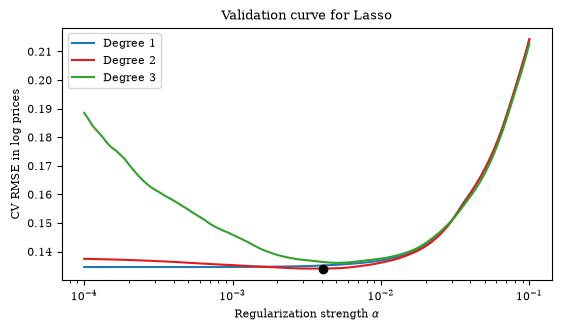

In [30]:
plot_validation_curves(lasso_cv, 'Lasso')

As with Ridge, each curve holds the degree fixed and varies $\alpha$. The black point
represents the best combination of degree and $\alpha$ found during cross-validation.
The selected alpha is clearly inside the grid. If it were at either endpoint,
we would need to expand the grid.

<span style="display: none;">SolutionEnd</span>

***
## Part 6 — Compare the results

1. Compare OLS, Ridge, and Lasso in a table showing the selected hyperparameters,
   CV RMSE, and test RMSE.
2. Which model would you choose using CV? Does the test ranking agree?
   How much difference does regularization make in this application?

Use CV for model selection and test errors to assess the fitted models.
The
[`root_mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html)
function computes RMSE.

### Solution

The following code compiles a summary table with the selected hyperparameters, number of coefficients, and CV RMSE, test RMSE, and test R² for each of the three models:

In [31]:
from sklearn.metrics import r2_score, root_mean_squared_error

model_names = ['OLS', 'Ridge', 'Lasso']
searches = [ols_cv, ridge_cv, lasso_cv]

# Compile a summary table of the cross-validation results
rows = []
for model_name, search in zip(model_names, searches):
    model = search.best_estimator_.named_steps['model']
    y_pred = search.best_estimator_.predict(X_test)

    rows.append(
        {
            'Model': model_name,
            'Degree': search.best_params_['poly__degree'],
            'Alpha': search.best_params_.get('model__alpha', np.nan),
            '# Coefs': len(model.coef_),
            '# Non-zero coefs': np.count_nonzero(np.abs(model.coef_) > 1e-8),
            'CV RMSE': -search.best_score_,
            'Test RMSE': root_mean_squared_error(y_test, y_pred),
            'Test R2': r2_score(y_test, y_pred),
        }
    )

df_cv = pd.DataFrame(rows).set_index('Model')
print(df_cv.to_string(float_format='{:.5g}'.format))

       Degree    Alpha  # Coefs  # Non-zero coefs  CV RMSE  Test RMSE  Test R2
Model                                                                         
OLS         1      NaN       12                12  0.13458    0.12692  0.90022
Ridge       1   4.6416       12                12  0.13458    0.12697  0.90013
Lasso       2 0.004037       90                37  0.13404    0.12316  0.90603


OLS and Ridge select degree 1, using the 12 numeric inputs directly.
Lasso selects degree 2, which generates 90 polynomial columns, and retains
37 nonzero coefficients.

Lasso performs best on both measures among these three models. Its selected
alpha is about 0.004037. Here, shrinkage allows a more flexible specification
while removing many of the expanded terms. Compared with OLS, Lasso reduces
CV RMSE by about 0.4% and test RMSE by about 3.0%, so the improvement from
regularization is small in this application.

<span style="display: none;">SolutionEnd</span>